# ✦ MUC02 | Credit Pre-Screening Engine
### Loan Intake Optimisation · BFSI / Retail Lending

**Prepared by:** Chetan Kalagarla  
**Batch:** Path 2 · KLU  
**Tools:** Python · Pandas · NumPy · Matplotlib · Seaborn · Scikit-learn

---

> **Project objective**  
> Use historical loan decisions to explore whether a logistic-regression pre-screener can identify clear-cut declines while limiting the risk of wrongly turning away applicants who were approved by the bank.

**Important interpretation:** the dataset's `decision` column records historical analyst judgement, not actual loan repayment. This is a learning prototype, not a production credit decision system.

#### Notebook roadmap
1. CBIM Problem Canvas
2. Step 5.1 — Load, inspect and clean
3. Step 5.2 — What drives approval today?
4. Step 5.3 — Engineer affordability features
5. Step 5.4 — Logistic regression pre-screener
6. Step 5.5 — Select the auto-decline threshold
7. Step 5.6 — Fairness check
8. Step 5.7 — Credit Policy Briefing

## 1. CBIM Problem Canvas

| Canvas field | Analysis |
|---|---|
| **Situation (S)** | A mid-size private bank receives approximately 3,000 personal-loan applications each month. Each application currently receives about 25 minutes of manual review. |
| **Complication (C)** | Analysts spend time reviewing applications that may be clear-cut declines, while other applicants may wait longer. Automating decisions carelessly could wrongly reject creditworthy applicants. |
| **Question (Q)** | Which applications, if any, could safely leave the manual-review queue, and at what confidence threshold, while keeping wrongly declined applicants at or below 5% of auto-declines? |
| **SSOT** | `MUC02_Credit_PreScreening_Dataset.csv`. The `decision` field represents the historical credit team's decision; it does **not** indicate whether the applicant repaid a loan. |
| **Success definition** | Select a threshold supported by the test-set analysis where no more than 5% of auto-declined cases were historically approved, then estimate monthly applications and analyst hours affected. |
| **Primary stakeholder** | Credit Policy Analyst. Other affected stakeholders include credit analysts and loan applicants. |

## 2. Setup and project configuration

**Before running:** put `MUC02_Credit_PreScreening_Dataset.csv` in the same folder as this notebook.

This notebook uses a consistent split (`stratify=y`, `random_state=42`) and avoids using `gender`, `city`, `application_id`, `application_date`, or `decision` as model features. Run all cells from top to bottom.

In [18]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    precision_score, recall_score, roc_auc_score
)

# Consistent, polished visual style
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {
    "navy": "#14213D",
    "blue": "#2563EB",
    "teal": "#0F766E",
    "gold": "#F4B942",
    "coral": "#E76F51",
    "purple": "#7C3AED",
    "grey": "#64748B",
}
plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "axes.titleweight": "bold",
    "axes.titlesize": 14,
    "axes.labelsize": 11,
    "figure.dpi": 110,
})

DATA_FILE = Path("MUC02_Credit_PreScreening_Dataset.csv")
if not DATA_FILE.exists():
    raise FileNotFoundError(
        "Dataset not found. Place MUC02_Credit_PreScreening_Dataset.csv "
        "in the same folder as this notebook, then run this cell again."
    )

df_raw = pd.read_csv(DATA_FILE)
print("Dataset loaded successfully")
print(f"Rows: {df_raw.shape[0]:,} | Columns: {df_raw.shape[1]}")
display(df_raw.head())

Dataset loaded successfully
Rows: 12,000 | Columns: 19


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined


## Step 5.1 — Load, inspect and clean

We inspect the dataset before changing it. The cleaning decisions are recorded so a reviewer can understand what changed and why.

In [19]:
print("Shape:", df_raw.shape)
print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nData types and non-null counts:")
df_raw.info()

print("\nMissing values by column:")
display(df_raw.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

print("\nDuplicate rows:", df_raw.duplicated().sum())

if "decision" not in df_raw.columns:
    raise ValueError("Required target column 'decision' is missing.")
print("\nHistorical decision counts:")
display(df_raw["decision"].value_counts(dropna=False).to_frame("count"))

approval_rate_raw = df_raw["decision"].astype(str).str.strip().str.lower().eq("approved").mean() * 100
print(f"Overall historical approval rate (including any rows with other target labels in denominator): {approval_rate_raw:.1f}%")

Shape: (12000, 19)

Column names:
['application_id', 'application_date', 'age', 'gender', 'city', 'city_tier', 'employment_type', 'years_in_current_job', 'monthly_income', 'existing_emi', 'credit_score', 'credit_history_months', 'num_active_loans', 'delinquencies_24m', 'loan_purpose', 'loan_amount', 'tenure_months', 'proposed_emi', 'decision']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   application_id         12000 non-null  str    
 1   application_date       12000 non-null  str    
 2   age                    12000 non-null  int64  
 3   gender                 12000 non-null  str    
 4   city                   12000 non-null  str    
 5   city_tier              12000 non-null  int64  
 6   employment_type        12000 non-null  str    
 7   years_in_current_job   12000 non-null  float64
 8 

,missing_count
credit_score,1039
monthly_income,441
application_id,0
age,0
application_date,0
gender,0
city,0
employment_type,0
city_tier,0
years_in_current_job,0



Duplicate rows: 0

Historical decision counts:


,count
decision,
Approved,6353
Declined,5647


Overall historical approval rate (including any rows with other target labels in denominator): 52.9%


### Cleaning decisions

- **Missing monthly income:** impute using the median within `employment_type`; if a whole employment group has no usable median, use the overall median.
- **Blank credit score:** these rows can represent new-to-credit applicants, not necessarily bad data. Create `is_ntc` before filling credit scores and retain these applicants.
- **Implausibly high monthly income:** the student brief identifies 12 salaried rows above ₹6,00,000/month as likely annual income entered as monthly. Divide those values by 12 and record the adjustment.
- **Other rows:** do not drop rows merely because any field is missing. The modelling pipeline handles remaining feature missingness where possible.

In [20]:
df = df_raw.copy()

# Normalise key text columns while preserving the original raw dataset above.
for col in ["decision", "employment_type", "loan_purpose", "gender"]:
    if col in df.columns:
        df[col] = df[col].astype("string").str.strip()

# Identify new-to-credit applicants BEFORE filling credit_score.
df["is_ntc"] = df["credit_score"].isna().astype(int)

# Repair annual-income-entered-as-monthly pattern, limited to Salaried applicants.
income_before = df["monthly_income"].copy()
salary_mask = (
    df["employment_type"].astype("string").str.lower().eq("salaried")
    & df["monthly_income"].gt(600000)
)
n_income_adjusted = int(salary_mask.sum())
df.loc[salary_mask, "monthly_income"] = df.loc[salary_mask, "monthly_income"] / 12

# Income imputation: median by employment type, then overall median as fallback.
missing_income_before = int(df["monthly_income"].isna().sum())
df["monthly_income"] = df.groupby("employment_type", dropna=False)["monthly_income"].transform(
    lambda s: s.fillna(s.median())
)
if df["monthly_income"].isna().any():
    df["monthly_income"] = df["monthly_income"].fillna(df["monthly_income"].median())

cleaning_log = pd.DataFrame({
    "Issue": [
        "Missing monthly_income",
        "Blank credit_score / new-to-credit",
        "Salaried monthly_income above ₹6,00,000",
    ],
    "Count identified": [
        missing_income_before,
        int(df_raw["credit_score"].isna().sum()),
        n_income_adjusted,
    ],
    "Action": [
        "Median imputation within employment_type; overall median fallback",
        "Retain rows; create is_ntc flag before score imputation",
        "Divide by 12 as likely annual income entered as monthly",
    ],
})
display(cleaning_log)

print("Rows retained:", len(df), "of", len(df_raw))
print("New-to-credit applicants retained:", int(df["is_ntc"].sum()))
print("Remaining missing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

,Issue,Count identified,Action
0,Missing monthly_income,441,Median imputation within employment_type; over...
1,Blank credit_score / new-to-credit,1039,Retain rows; create is_ntc flag before score i...
2,"Salaried monthly_income above ₹6,00,000",12,Divide by 12 as likely annual income entered a...


Rows retained: 12000 of 12000
New-to-credit applicants retained: 1039
Remaining missing values:


,missing_count
credit_score,1039
application_id,0
age,0
application_date,0
gender,0
city,0
employment_type,0
city_tier,0
years_in_current_job,0
monthly_income,0


### Step 5.1 — Interpretation

Review the cleaning log and the remaining missing-value table. The new-to-credit flag is important because a blank credit score may indicate no credit history. These applicants should not silently disappear from the analysis.

## Step 5.2 — What drives approval today?

We compare historical approval rates across credit-score bands and employment types. These are descriptions of past decisions, not proof of repayment performance or causal effects.

,applications,approval_rate_pct
credit_score_band,,
Below 600,246,2.0
600–649,933,3.2
650–699,2529,32.5
700–749,3377,54.4
750–799,2526,77.2
800+,1350,85.2
No score,1039,53.9


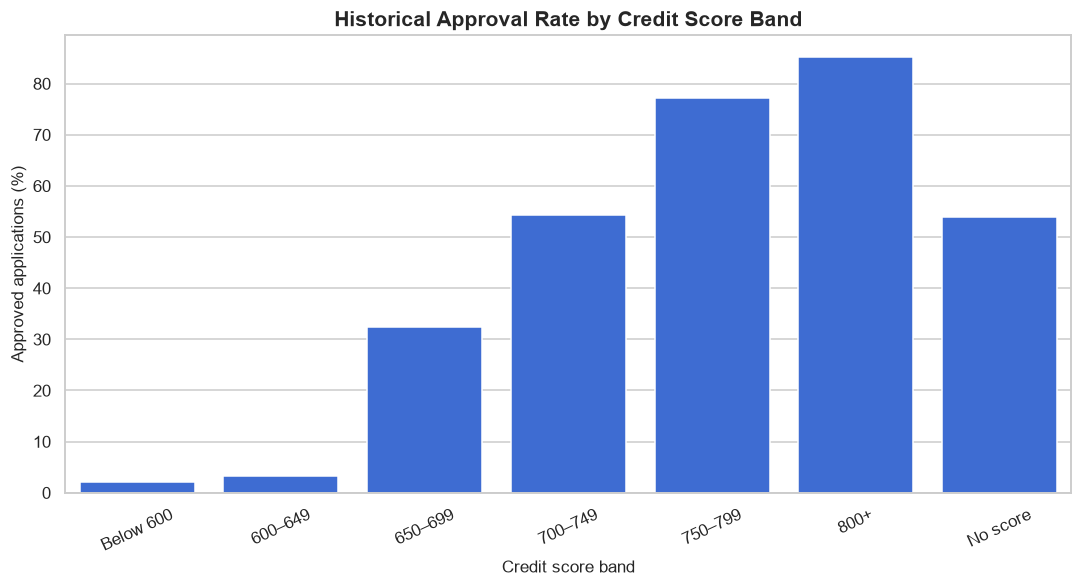

,applications,approval_rate_pct
employment_type,,
Salaried,7057,58.4
Business Owner,1749,51.2
Self-Employed Professional,1428,50.6
Gig / Contract,1766,34.9


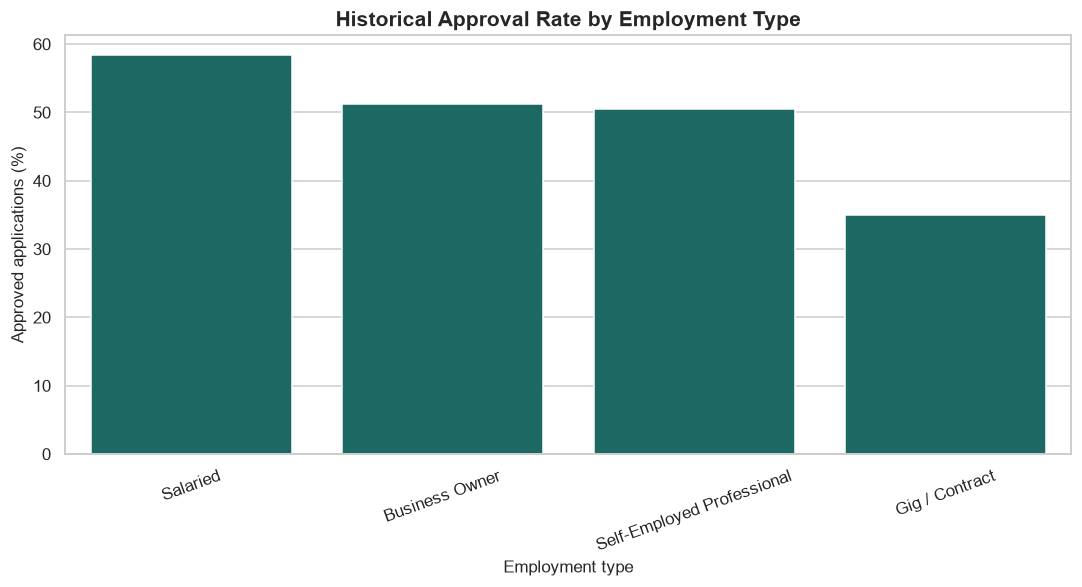

Interpretation prompts:
1. Compare approval just below and above a score of 650.
2. Compare the no-score group with scored applicants.
3. Which employment type has the lowest approval rate?


In [21]:
analysis_df = df.copy()
analysis_df["decision_clean"] = analysis_df["decision"].astype("string").str.strip().str.lower()
analysis_df["approved_flag"] = analysis_df["decision_clean"].eq("approved").astype(int)

score = pd.to_numeric(analysis_df["credit_score"], errors="coerce")
score_bins = [-np.inf, 599, 649, 699, 749, 799, np.inf]
score_labels = ["Below 600", "600–649", "650–699", "700–749", "750–799", "800+"]
analysis_df["credit_score_band"] = pd.cut(score, bins=score_bins, labels=score_labels)
analysis_df["credit_score_band"] = analysis_df["credit_score_band"].cat.add_categories(["No score"])
analysis_df.loc[score.isna(), "credit_score_band"] = "No score"

score_order = score_labels + ["No score"]
approval_by_score = (
    analysis_df.groupby("credit_score_band", observed=False)["approved_flag"]
    .agg(approval_rate="mean", applications="size")
    .reindex(score_order)
)
approval_by_score["approval_rate_pct"] = approval_by_score["approval_rate"] * 100
display(approval_by_score[["applications", "approval_rate_pct"]].round(1))

fig, ax = plt.subplots()
sns.barplot(
    data=approval_by_score.reset_index(),
    x="credit_score_band", y="approval_rate_pct",
    color=PALETTE["blue"], ax=ax
)
ax.set_title("Historical Approval Rate by Credit Score Band")
ax.set_xlabel("Credit score band")
ax.set_ylabel("Approved applications (%)")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

approval_by_employment = (
    analysis_df.groupby("employment_type", dropna=False)["approved_flag"]
    .agg(approval_rate="mean", applications="size")
    .sort_values("approval_rate", ascending=False)
)
approval_by_employment["approval_rate_pct"] = approval_by_employment["approval_rate"] * 100
display(approval_by_employment[["applications", "approval_rate_pct"]].round(1))

fig, ax = plt.subplots()
sns.barplot(
    data=approval_by_employment.reset_index(),
    x="employment_type", y="approval_rate_pct",
    color=PALETTE["teal"], ax=ax
)
ax.set_title("Historical Approval Rate by Employment Type")
ax.set_xlabel("Employment type")
ax.set_ylabel("Approved applications (%)")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

print("Interpretation prompts:")
print("1. Compare approval just below and above a score of 650.")
print("2. Compare the no-score group with scored applicants.")
print("3. Which employment type has the lowest approval rate?")

## Step 5.3 — Engineer affordability features

**Definitions**
- `foir = (existing_emi + proposed_emi) / monthly_income`
- `loan_to_income = loan_amount / (monthly_income × 12)`
- `is_ntc = 1` if credit score was missing originally; otherwise `0`

FOIR is the share of monthly income committed to existing and proposed EMIs. We cap only the *plotting groups* at the requested bands; the underlying numeric feature remains uncapped.

,applications,approval_rate_pct
foir_band,,
Below 30%,5491,65.5
30–40%,2497,59.0
40–50%,1766,47.8
50–55%,531,32.4
Above 55%,1715,15.6


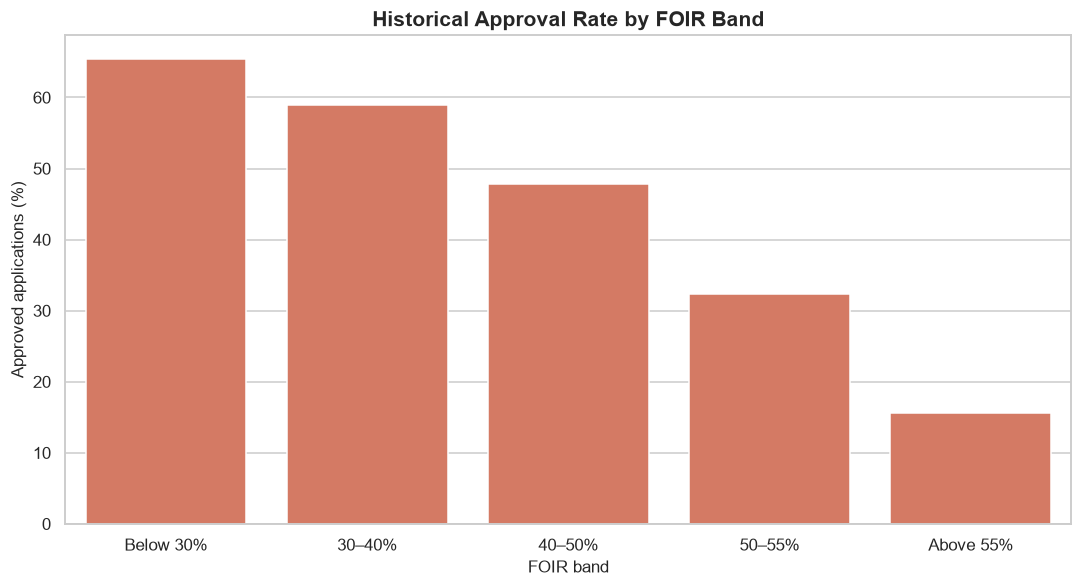

FOIR median: 0.317
Loan-to-income median: 0.519
Interpretation: identify where the approval rate drops sharply and propose a policy limit supported by the chart.


In [22]:
# Avoid division by zero or negative incomes.
income_denominator = pd.to_numeric(df["monthly_income"], errors="coerce").where(
    pd.to_numeric(df["monthly_income"], errors="coerce") > 0
)
df["foir"] = (
    pd.to_numeric(df["existing_emi"], errors="coerce")
    + pd.to_numeric(df["proposed_emi"], errors="coerce")
) / income_denominator

df["loan_to_income"] = pd.to_numeric(df["loan_amount"], errors="coerce") / (income_denominator * 12)

foir_bins = [-np.inf, 0.30, 0.40, 0.50, 0.55, np.inf]
foir_labels = ["Below 30%", "30–40%", "40–50%", "50–55%", "Above 55%"]
df["foir_band"] = pd.cut(df["foir"], bins=foir_bins, labels=foir_labels, right=False)

df["decision_clean"] = df["decision"].astype("string").str.strip().str.lower()
df["approved_flag"] = df["decision_clean"].eq("approved").astype(int)

approval_by_foir = (
    df.groupby("foir_band", observed=False)["approved_flag"]
    .agg(approval_rate="mean", applications="size")
    .reindex(foir_labels)
)
approval_by_foir["approval_rate_pct"] = approval_by_foir["approval_rate"] * 100
display(approval_by_foir[["applications", "approval_rate_pct"]].round(1))

fig, ax = plt.subplots()
sns.barplot(
    data=approval_by_foir.reset_index(),
    x="foir_band", y="approval_rate_pct",
    color=PALETTE["coral"], ax=ax
)
ax.set_title("Historical Approval Rate by FOIR Band")
ax.set_xlabel("FOIR band")
ax.set_ylabel("Approved applications (%)")
plt.tight_layout()
plt.show()

print("FOIR median:", round(df["foir"].median(), 3))
print("Loan-to-income median:", round(df["loan_to_income"].median(), 3))
print("Interpretation: identify where the approval rate drops sharply and propose a policy limit supported by the chart.")

## Step 5.4 — Build the logistic-regression pre-screener

The target is **Declined = 1** and **Approved = 0**. Therefore, a positive prediction means the model predicts a historical decline.

We exclude `application_id`, `application_date`, `city`, `gender`, and `decision` from the feature set. We retain `city_tier`, as required in the student instructions. Numeric features are imputed and scaled; categorical features are imputed and one-hot encoded.

Accuracy: 0.791 (79.1%)
Precision (Declined class): 0.791
Recall (Declined class): 0.755
ROC-AUC: 0.867


,Predicted Approved (0),Predicted Declined (1)
Actually Approved (0),1046,225
Actually Declined (1),277,852


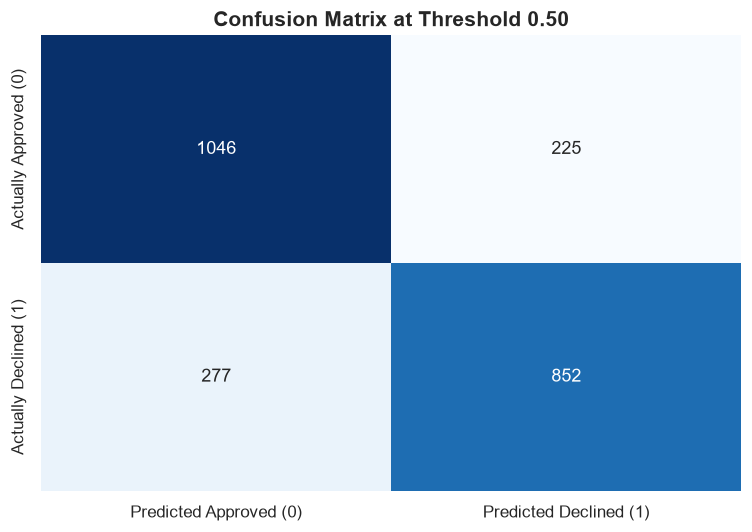

At 0.50, wrongly declined historically approved applicants (FP): 225
Historically declined applicants missed by the model (FN): 277


,feature,coefficient
0,numeric__foir,1.219570
1,numeric__credit_score,-1.009794
2,numeric__delinquencies_24m,0.978713
3,categorical__employment_type_Gig / Contract,0.618781
4,categorical__employment_type_Salaried,-0.444486


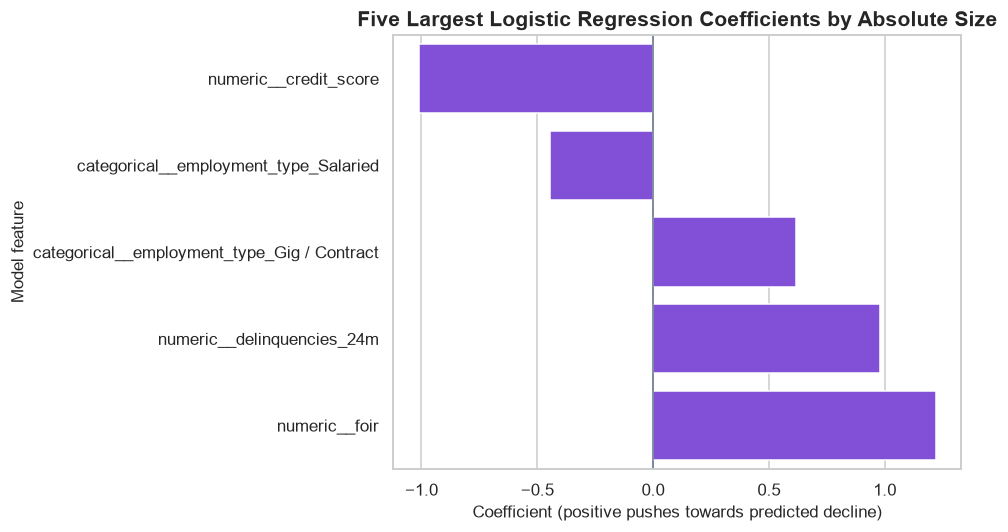

Business interpretation: positive coefficients push predictions towards Declined; negative coefficients push towards Approved.
Coefficients describe associations learned from historical decisions, not causal effects.


In [23]:
# Keep only rows with a known Approved/Declined target.
model_df = df.copy()
model_df["decision_clean"] = model_df["decision"].astype("string").str.strip().str.lower()
model_df = model_df[model_df["decision_clean"].isin(["approved", "declined"])].copy()
y = model_df["decision_clean"].eq("declined").astype(int)

numeric_features = [
    "credit_score", "is_ntc", "foir", "loan_to_income",
    "delinquencies_24m", "num_active_loans", "years_in_current_job",
    "age", "tenure_months", "city_tier"
]
categorical_features = ["employment_type", "loan_purpose"]
feature_columns = numeric_features + categorical_features

missing_features = [c for c in feature_columns if c not in model_df.columns]
if missing_features:
    raise ValueError(f"Required model features missing from dataset: {missing_features}")

X = model_df[feature_columns].copy()

# Ensure numeric columns are numeric and categorical columns are strings.
for c in numeric_features:
    X[c] = pd.to_numeric(X[c], errors="coerce")
for c in categorical_features:
    X[c] = X[c].astype("string").fillna("Unknown").astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000, random_state=42))
])
model.fit(X_train, y_train)

y_pred_05 = model.predict(X_test)
decline_probability = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred_05)
precision_declined = precision_score(y_test, y_pred_05, pos_label=1, zero_division=0)
recall_declined = recall_score(y_test, y_pred_05, pos_label=1, zero_division=0)
roc_auc = roc_auc_score(y_test, decline_probability)

print(f"Accuracy: {accuracy:.3f} ({accuracy*100:.1f}%)")
print(f"Precision (Declined class): {precision_declined:.3f}")
print(f"Recall (Declined class): {recall_declined:.3f}")
print(f"ROC-AUC: {roc_auc:.3f}")

cm = confusion_matrix(y_test, y_pred_05, labels=[0, 1])
cm_display = pd.DataFrame(
    cm,
    index=["Actually Approved (0)", "Actually Declined (1)"],
    columns=["Predicted Approved (0)", "Predicted Declined (1)"]
)
display(cm_display)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm_display, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Confusion Matrix at Threshold 0.50")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"At 0.50, wrongly declined historically approved applicants (FP): {fp}")
print(f"Historically declined applicants missed by the model (FN): {fn}")

# Coefficients after preprocessing.
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coefficients = model.named_steps["classifier"].coef_[0]
coef_df = pd.DataFrame({"feature": feature_names, "coefficient": coefficients})
coef_df["abs_coefficient"] = coef_df["coefficient"].abs()
top_coefficients = coef_df.sort_values("abs_coefficient", ascending=False).head(5)
display(top_coefficients[["feature", "coefficient"]].reset_index(drop=True))

fig, ax = plt.subplots(figsize=(9, 5))
plot_coef = top_coefficients.sort_values("coefficient")
sns.barplot(data=plot_coef, x="coefficient", y="feature", color=PALETTE["purple"], ax=ax)
ax.axvline(0, color=PALETTE["grey"], linewidth=1)
ax.set_title("Five Largest Logistic Regression Coefficients by Absolute Size")
ax.set_xlabel("Coefficient (positive pushes towards predicted decline)")
ax.set_ylabel("Model feature")
plt.tight_layout()
plt.show()

print("Business interpretation: positive coefficients push predictions towards Declined; negative coefficients push towards Approved.")
print("Coefficients describe associations learned from historical decisions, not causal effects.")

## Step 5.5 — Set the auto-decline threshold

The bank's stated risk rule is: **no more than 5% of auto-declined applications should be applications that were historically approved.**

For each threshold, we calculate:
1. Percentage of test applications that would be auto-declined.
2. Percentage of those auto-declines that were historically approved (wrongly declined).

The selected threshold is the **lowest threshold that satisfies the 5% rule**, because it auto-declines the largest share among the tested thresholds that meet the rule. This is a simulation on historical decisions, not a guarantee of future safety.

,threshold,auto_declined_pct,wrongly_declined_pct_of_auto_declines,declines_caught_pct,auto_declined_test_count,wrong_declined_test_count
0,0.50,44.88,20.89,75.47,1077,225
1,0.60,37.62,16.83,66.52,903,152
2,0.70,30.75,12.06,57.48,738,89
3,0.80,23.46,7.10,46.32,563,40
4,0.85,19.67,5.93,39.33,472,28
5,0.90,15.21,4.66,30.82,365,17
6,0.95,10.00,2.08,20.81,240,5


Recommended tested threshold: 0.90
Auto-declined: 15.2% of test applications
Wrongly declined: 4.7% of auto-declines


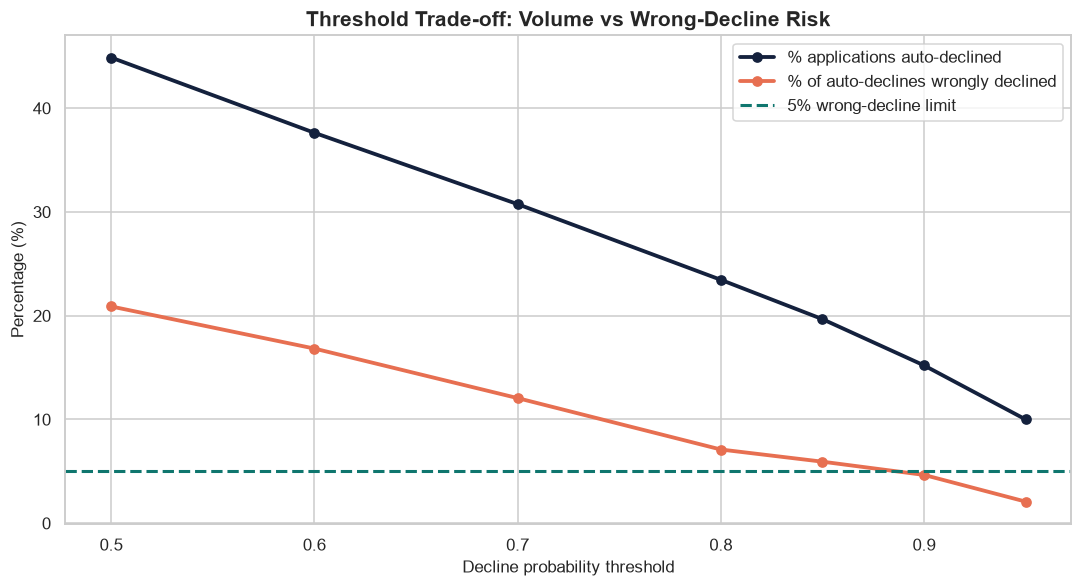

Estimated monthly applications auto-declined: 456 of 3,000
Estimated analyst time freed: 190.1 hours/month
Estimated monthly wrongly declined (based on test-set rate): 21


In [24]:
thresholds = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]
threshold_rows = []
y_test_array = np.asarray(y_test)

for threshold in thresholds:
    auto_decline = decline_probability >= threshold
    n_auto = int(auto_decline.sum())
    pct_auto = (n_auto / len(y_test_array) * 100) if len(y_test_array) else np.nan
    # Target 0 = historically Approved, 1 = historically Declined.
    wrong_declines = int(((y_test_array == 0) & auto_decline).sum())
    wrong_pct = (wrong_declines / n_auto * 100) if n_auto else 0.0
    declines_caught = int(((y_test_array == 1) & auto_decline).sum())
    actual_declines = int((y_test_array == 1).sum())
    pct_actual_declines_caught = declines_caught / actual_declines * 100 if actual_declines else np.nan
    threshold_rows.append({
        "threshold": threshold,
        "auto_declined_pct": pct_auto,
        "wrongly_declined_pct_of_auto_declines": wrong_pct,
        "declines_caught_pct": pct_actual_declines_caught,
        "auto_declined_test_count": n_auto,
        "wrong_declined_test_count": wrong_declines
    })

threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(2))

valid_thresholds = threshold_table[
    threshold_table["wrongly_declined_pct_of_auto_declines"] <= 5.0
]
if valid_thresholds.empty:
    chosen_threshold = None
    print("No tested threshold met the 5% rule. Do not claim a compliant auto-decline threshold.")
else:
    chosen_threshold = float(valid_thresholds.sort_values("threshold").iloc[0]["threshold"])
    selected_row = threshold_table.loc[threshold_table["threshold"].eq(chosen_threshold)].iloc[0]
    print(f"Recommended tested threshold: {chosen_threshold:.2f}")
    print(f"Auto-declined: {selected_row['auto_declined_pct']:.1f}% of test applications")
    print(f"Wrongly declined: {selected_row['wrongly_declined_pct_of_auto_declines']:.1f}% of auto-declines")

fig, ax = plt.subplots()
ax.plot(
    threshold_table["threshold"], threshold_table["auto_declined_pct"],
    marker="o", linewidth=2.5, color=PALETTE["navy"], label="% applications auto-declined"
)
ax.plot(
    threshold_table["threshold"], threshold_table["wrongly_declined_pct_of_auto_declines"],
    marker="o", linewidth=2.5, color=PALETTE["coral"], label="% of auto-declines wrongly declined"
)
ax.axhline(5, color=PALETTE["teal"], linestyle="--", linewidth=2, label="5% wrong-decline limit")
ax.set_title("Threshold Trade-off: Volume vs Wrong-Decline Risk")
ax.set_xlabel("Decline probability threshold")
ax.set_ylabel("Percentage (%)")
ax.legend(frameon=True)
plt.tight_layout()
plt.show()

if chosen_threshold is not None:
    selected_row = threshold_table.loc[threshold_table["threshold"].eq(chosen_threshold)].iloc[0]
    monthly_applications = 3000
    minutes_per_review = 25
    monthly_auto_declines = monthly_applications * selected_row["auto_declined_pct"] / 100
    monthly_hours_freed = monthly_auto_declines * minutes_per_review / 60
    print(f"Estimated monthly applications auto-declined: {monthly_auto_declines:.0f} of 3,000")
    print(f"Estimated analyst time freed: {monthly_hours_freed:.1f} hours/month")
    print(f"Estimated monthly wrongly declined (based on test-set rate): "
          f"{monthly_auto_declines * selected_row['wrongly_declined_pct_of_auto_declines']/100:.0f}")
else:
    monthly_applications = 3000
    monthly_hours_freed = np.nan
    print("Business impact cannot be recommended until a tested threshold meets the 5% rule.")

### Step 5.5 — Business interpretation

Do not report accuracy alone. The important trade-off is how many applications can be auto-declined while keeping the proportion of historically approved applicants within the bank's 5% risk limit. Monthly hours are estimated as:

**Monthly applications auto-declined × 25 minutes ÷ 60**

This is potential review time released, not necessarily cash savings. A strict threshold may affect fewer applications, which can be appropriate when protecting creditworthy applicants is the priority.

## Step 5.6 — Fairness check

Gender is **not** used as a model feature. We still compare historical approval rates, income and employment mix by gender, and the model's auto-decline rate at the chosen threshold. Leaving gender out does not by itself guarantee fairness because other variables may act as proxies.

Historical approval rate by gender:


,approval_rate_pct
gender_group,
Female,50.4
Male,54.1


Historical approval rate by gender within employment type:


,employment_type,gender_group,approval_rate_pct
0,Business Owner,Female,51.6
1,Business Owner,Male,51.1
2,Gig / Contract,Female,34.6
3,Gig / Contract,Male,35.2
4,Salaried,Female,56.8
5,Salaried,Male,59.1
6,Self-Employed Professional,Female,47.6
7,Self-Employed Professional,Male,52.0


Median monthly income and Gig / Contract share by gender:


,applications,median_monthly_income,gig_contract_share_pct
gender_group,,,
Female,3795,45000.0,21.4
Male,8205,55000.0,11.6


Model auto-decline rate by gender at threshold 0.90:


,auto_decline_rate_pct
gender_group,
Female,15.6
Male,15.0


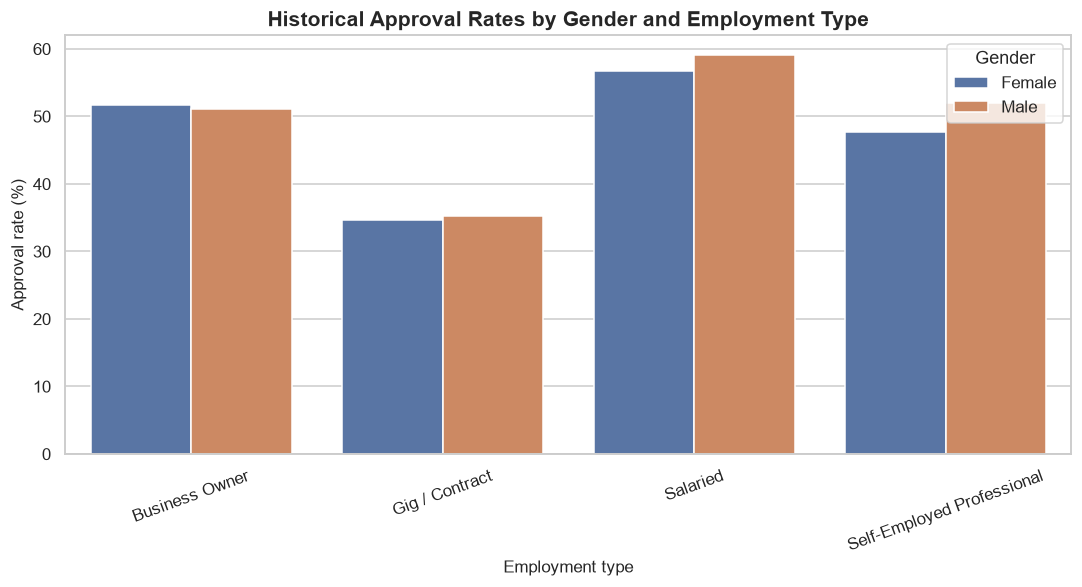

In [25]:
if "gender" not in df.columns:
    print("Gender column not available; fairness comparison cannot be completed.")
else:
    fairness_df = df.copy()
    fairness_df["gender_group"] = fairness_df["gender"].astype("string").fillna("Unknown")
    fairness_df["decision_clean"] = fairness_df["decision"].astype("string").str.strip().str.lower()
    fairness_df["approved_flag"] = fairness_df["decision_clean"].eq("approved").astype(int)

    print("Historical approval rate by gender:")
    gender_approval = fairness_df.groupby("gender_group")["approved_flag"].mean().mul(100).rename("approval_rate_pct")
    display(gender_approval.to_frame().round(1))

    print("Historical approval rate by gender within employment type:")
    gender_employment = (
        fairness_df.groupby(["employment_type", "gender_group"], dropna=False)["approved_flag"]
        .mean().mul(100).rename("approval_rate_pct").reset_index()
    )
    display(gender_employment.round(1))

    print("Median monthly income and Gig / Contract share by gender:")
    fairness_df["is_gig_contract"] = (
        fairness_df["employment_type"].astype("string").str.lower().eq("gig / contract")
    )
    gender_income_mix = fairness_df.groupby("gender_group").agg(
        median_monthly_income=("monthly_income", "median"),
        gig_contract_share=("is_gig_contract", "mean"),
        applications=("gender_group", "size")
    )
    gender_income_mix["gig_contract_share_pct"] = gender_income_mix["gig_contract_share"] * 100
    display(gender_income_mix[["applications", "median_monthly_income", "gig_contract_share_pct"]].round(1))

    if chosen_threshold is not None:
        X_test_fair = X_test.copy()
        auto_decline_selected = decline_probability >= chosen_threshold
        test_gender = model_df.loc[X_test.index, "gender"].astype("string").fillna("Unknown")
        gender_auto_rate = pd.DataFrame({
            "gender_group": test_gender.to_numpy(),
            "auto_declined": auto_decline_selected.astype(int)
        }).groupby("gender_group")["auto_declined"].mean().mul(100).rename("auto_decline_rate_pct")
        print(f"Model auto-decline rate by gender at threshold {chosen_threshold:.2f}:")
        display(gender_auto_rate.to_frame().round(1))
    else:
        print("No compliant threshold was found, so model auto-decline rates are not presented as a recommendation.")

    fig, ax = plt.subplots()
    sns.barplot(
        data=gender_employment,
        x="employment_type", y="approval_rate_pct", hue="gender_group", ax=ax
    )
    ax.set_title("Historical Approval Rates by Gender and Employment Type")
    ax.set_xlabel("Employment type")
    ax.set_ylabel("Approval rate (%)")
    ax.tick_params(axis="x", rotation=20)
    ax.legend(title="Gender")
    plt.tight_layout()
    plt.show()

### Step 5.6 — Fairness interpretation

Use the tables above to write 3–4 sentences:
- Is there a historical approval-rate gap overall?
- Does the gap remain within employment types, or does income/job mix appear relevant?
- Does the model's auto-decline rate differ by gender at the selected threshold?
- Gender should not be added casually as a feature; leaving it out is not enough. Monitor outcomes for proxy effects after deployment.

## Step 5.7 — Credit Policy Briefing

Complete this final stakeholder briefing using **your own outputs** from Steps 5.2–5.6. Replace the bracketed items before submitting. Keep it to 4–6 sentences.

> I recommend a decline-probability threshold of **[threshold]**, which would auto-decline approximately **[X]%** of applications, or **[N] of 3,000 applications per month**, freeing an estimated **[H] analyst hours per month** while keeping the share of historically approved applicants among auto-declines at **[Y]%**. The strongest drivers in my model are **[driver 1 and coefficient/result]** and **[driver 2 and coefficient/result]**. New-to-credit applicants should continue to receive human review because their blank credit scores indicate limited credit history and the model may be less reliable for this group. Gender was excluded from the features, but income and employment type may act as proxies, so I recommend monitoring outcomes by gender and employment type. Before going live, the bank should validate the model against actual repayment/default outcomes, because the current target records past analyst decisions rather than repayment performance.

**Do not present the bracketed template as a completed result.** Fill it with the values printed by your notebook. If no tested threshold meets the 5% rule, say so and recommend further review rather than claiming compliance.

In [26]:
# Automatically assemble a draft briefing using the computed values.
# Review the wording and confirm the numbers before submission.
if chosen_threshold is not None:
    selected_row = threshold_table.loc[threshold_table["threshold"].eq(chosen_threshold)].iloc[0]
    monthly_auto = 3000 * selected_row["auto_declined_pct"] / 100
    monthly_hours = monthly_auto * 25 / 60
    briefing = (
        f"I recommend a decline-probability threshold of {chosen_threshold:.2f}. "
        f"On the test set, this would auto-decline {selected_row['auto_declined_pct']:.1f}% of applications; "
        f"scaled to 3,000 monthly applications, that is about {monthly_auto:.0f} applications and "
        f"{monthly_hours:.1f} analyst hours of review time. "
        f"At this threshold, {selected_row['wrongly_declined_pct_of_auto_declines']:.1f}% of auto-declines were "
        f"historically approved, compared with the bank's 5% limit. "
        "The model's largest coefficients are listed in Step 5.4; interpret their direction using the coefficient table. "
        "New-to-credit applicants should remain under human review until the model is validated for this group. "
        "Gender was excluded, but proxy effects should be monitored; actual repayment/default data is needed before deployment."
    )
else:
    briefing = (
        "None of the tested thresholds met the bank's 5% wrong-decline limit. "
        "I do not recommend auto-declining applications on the current evidence. "
        "The bank should review the model and test additional thresholds, retain human review, and validate against actual repayment/default outcomes. "
        "The coefficient table and fairness analysis should be used to identify risk factors and possible proxy effects before any deployment."
    )
display(Markdown("### Draft briefing based on this run\n\n" + briefing))

### Draft briefing based on this run

I recommend a decline-probability threshold of 0.90. On the test set, this would auto-decline 15.2% of applications; scaled to 3,000 monthly applications, that is about 456 applications and 190.1 analyst hours of review time. At this threshold, 4.7% of auto-declines were historically approved, compared with the bank's 5% limit. The model's largest coefficients are listed in Step 5.4; interpret their direction using the coefficient table. New-to-credit applicants should remain under human review until the model is validated for this group. Gender was excluded, but proxy effects should be monitored; actual repayment/default data is needed before deployment.

### Limitations
- The target is the historical credit team's decision, not repayment/default.
- Threshold results estimate performance on a held-out test set; they do not guarantee future outcomes.
- A group-level fairness check is a first diagnostic, not proof of fairness.
- This prototype is for coursework and should not be used to make real lending decisions.